<a href="https://colab.research.google.com/github/ab110404/MAT422/blob/main/HW3.7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW 3.7
3.7.1. Mathematical formulation
- In this example, I will create a simple neural network with two inputs and one output using Python.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
  return 1 / (1 + np.exp(-z))
def neural_network(x1, x2, w1, w2, b):
  z = w1*x1 + w2*x2 + b
  return sigmoid(z)
x1 = 2
x2 = 3
w1 = 0.5
w2 = 0.8
b = -1
prediction = neural_network(x1, x2, w1, w2, b)
print("Weighted sum:", w1*x1 + w2*x2 + b)
print("Predicted output:", round(prediction, 4))

Weighted sum: 2.4000000000000004
Predicted output: 0.9168


- I will now change the bias to observe how it affects the predicted output.

In [2]:
bias_values = [-2, -1, 0, 1]
for bias in bias_values:
  output = neural_network(x1, x2, w1, w2, bias)
  print(
      f"Bias = {bias}, "
      f"Predicted output = {output:.4f}"
  )

Bias = -2, Predicted output = 0.8022
Bias = -1, Predicted output = 0.9168
Bias = 0, Predicted output = 0.9677
Bias = 1, Predicted output = 0.9879


Now I will graph the sigmoid function to visualize how it transforms input values.

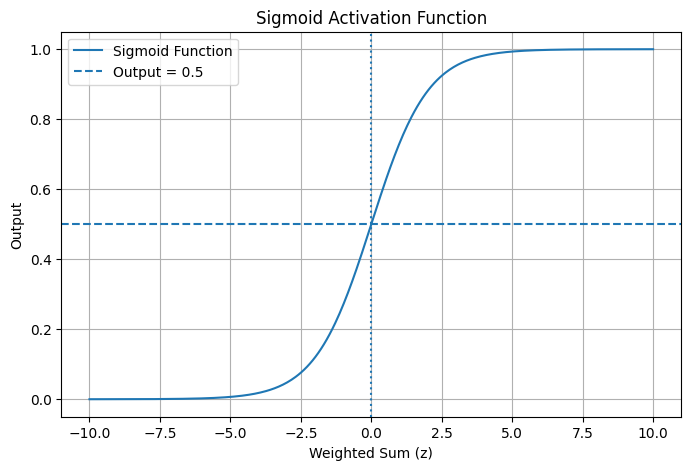

In [3]:
z_values = np.linspace(-10, 10, 400)
outputs = sigmoid(z_values)
plt.figure(figsize=(8, 5))
plt.plot(z_values, outputs, label="Sigmoid Function")
plt.axhline(0.5, linestyle="--", label="Output = 0.5")
plt.axvline(0, linestyle=":")
plt.xlabel("Weighted Sum (z)")
plt.ylabel("Output")
plt.title("Sigmoid Activation Function")
plt.legend()
plt.grid(True)
plt.show()

- I will use the same weights and bias but change the two inputs
- This will demonstrate how input values influence the output of a neural network

In [4]:
input_data = np.array([
    [1, 1],
    [2, 3],
    [3, 2],
    [4, 5]
])
for inputs in input_data:
  output = neural_network(
      inputs[0], inputs[1], w1, w2, b
  )
  print(
      f"Inputs = {inputs}, "
      f"Prediction = {output:.4f}"
  )

Inputs = [1 1], Prediction = 0.5744
Inputs = [2 3], Prediction = 0.9168
Inputs = [3 2], Prediction = 0.8909
Inputs = [4 5], Prediction = 0.9933


- I will create a diagram to visualize this structure.

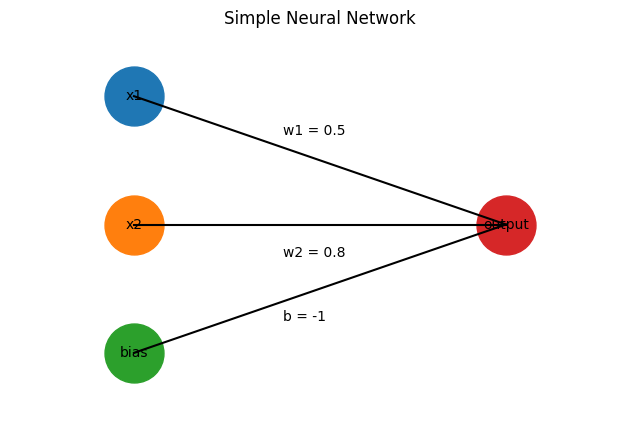

In [5]:
plt.figure(figsize=(8, 5))
nodes = {
    "x1": (0, 2),
    "x2": (0, 0),
    "bias": (0, -2),
    "output": (3, 0)
}
for name, (x, y) in nodes.items():
  plt.scatter(x, y, s=1800)
  plt.text(x, y, name, ha="center", va="center")
for start in ["x1", "x2", "bias"]:
  x_start, y_start = nodes[start]
  x_end, y_end = nodes["output"]
  plt.plot(
      [x_start, x_end],
      [y_start, y_end],
      color="black"
  )
plt.text(1.2, 1.4, "w1 = 0.5")
plt.text(1.2, -0.5, "w2 = 0.8")
plt.text(1.2, -1.5, "b = -1")
plt.title("Simple Neural Network")
plt.xlim(-1, 4)
plt.ylim(-3, 3)
plt.axis("off")
plt.show()

- I will train a simple neuron on a small binary dataset and observe how its prediction improve.

In [6]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)
y = np.array([0, 0, 0, 1], dtype=float)
weights = np.zeros(2)
bias = 0.0
learning_rate = 0.5
loss_history = []
for epoch in range(1000):
  z = X @ weights + bias
  predictions = sigmoid(z)
  eps = 1e-12
  loss = -np.mean(
      y*np.log(predictions + eps)
      + (1-y)*np.log(1-predictions + eps)
  )
  loss_history.append(loss)

  error = predictions - y
  dw = X.T @ error / len(y)
  db = np.mean(error)

  weights -= learning_rate * dw
  bias -= learning_rate * db

final_predictions = sigmoid(X @ weights + bias)
print("Learned weights:", np.round(weights, 4))
print("Learned bias:", round(bias, 4))
print("Predictions:", np.round(final_predictions, 4))
print("Final loss:", round(loss_history[-1], 4))

Learned weights: [6.0141 6.0141]
Learned bias: -9.1984
Predictions: [1.000e-04 3.980e-02 3.980e-02 9.443e-01]
Final loss: 0.0347


- During training, the neural network updates its weights and bias to reduce prediction error.
- I will plot the loss over the training iterations

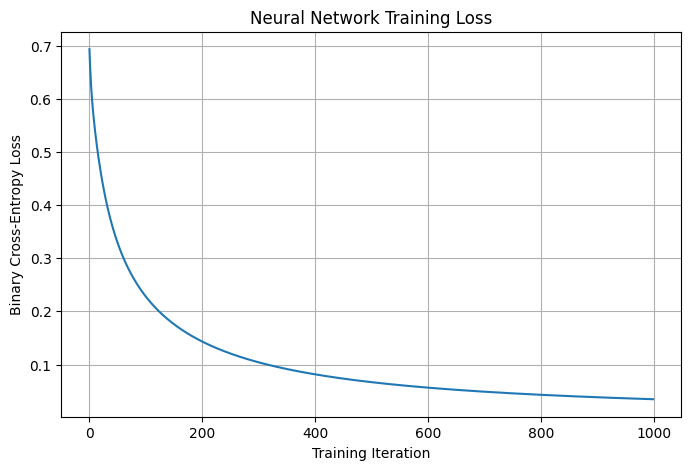

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Training Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training Loss")
plt.grid(True)
plt.show()

- In this section, I explored the mathematical formulation of a simple neural network.
- This example demonstrates how neural networks use mathematical operations and optimization to learn relationships between inputs and outputs.

3.7.2. Activation functions
- In this example, I will explore the Step, ReLu, and Sigmoid activation function using Python.

In [8]:
def step_function(x):
  return np.where(np.asarray(x) >= 0, 1, 0)
def relu(x):
  return np.maximum(0, x)
def sigmoid(x):
  return 1 / (1 + np.exp(-x))
x = np.array([-3, -2, -1, 0, 1, 2, 3])
print("Input values:", x)
print("Step:", step_function(x))
print("ReLu:", relu(x))
print("Sigmoid:", np.round(sigmoid(x), 4))

Input values: [-3 -2 -1  0  1  2  3]
Step: [0 0 0 1 1 1 1]
ReLu: [0 0 0 0 1 2 3]
Sigmoid: [0.0474 0.1192 0.2689 0.5    0.7311 0.8808 0.9526]


- I will now graph the Step function to visualize its behavior.
- The Step function produces an output of either 0 or 1.

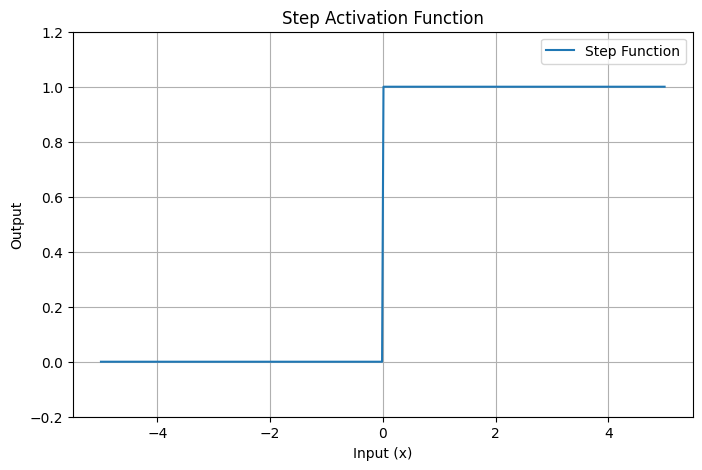

In [9]:
x_values = np.linspace(-5, 5, 400)
plt.figure(figsize=(8, 5))
plt.plot(
    x_values,
    step_function(x_values),
    label="Step Function"
)
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.title("Step Activation Function")
plt.ylim(-0.2, 1.2)
plt.legend()
plt.grid(True)
plt.show()

- I will graph the ReLu function to understand its shape.

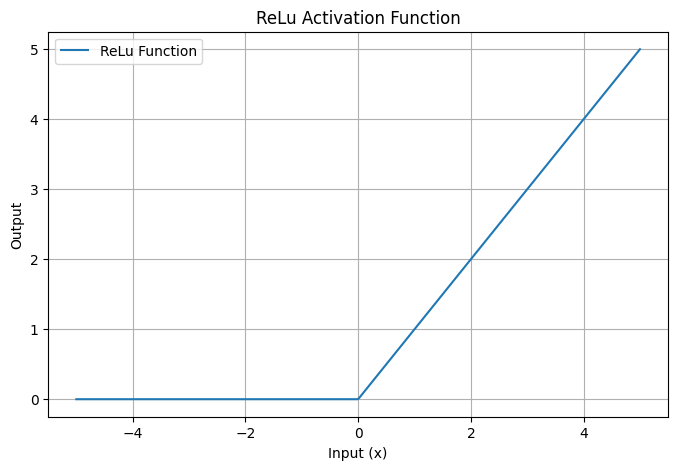

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(
    x_values,
    relu(x_values),
    label="ReLu Function"
)
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.title("ReLu Activation Function")
plt.legend()
plt.grid(True)
plt.show()

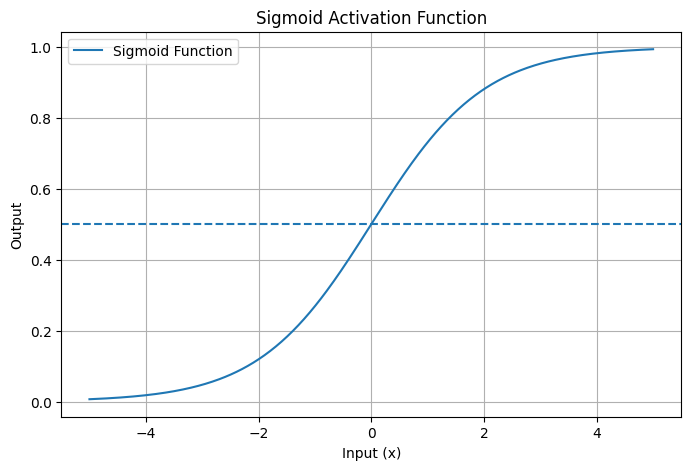

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(
    x_values,
    sigmoid(x_values),
    label="Sigmoid Function"
)
plt.axhline(0.5, linestyle="--")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.title("Sigmoid Activation Function")
plt.legend()
plt.grid(True)
plt.show()

Now I will graph all three functions together to compare their behavior.

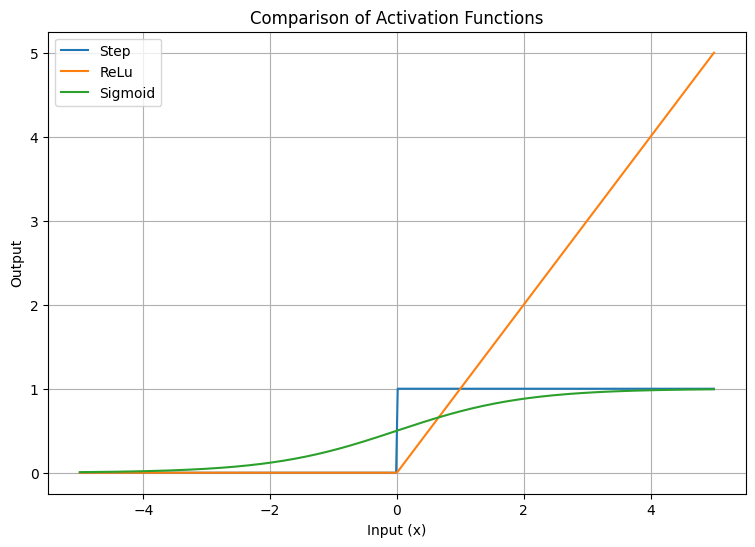

In [12]:
plt.figure(figsize=(9, 6))
plt.plot(
    x_values,
    step_function(x_values),
    label="Step"
)
plt.plot(
    x_values,
    relu(x_values),
    label="ReLu"
)
plt.plot(
    x_values,
    sigmoid(x_values),
    label="Sigmoid"
)
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.title("Comparison of Activation Functions")
plt.legend()
plt.grid(True)
plt.show()

I will apply three different activation functions to the same weighted sum and compare their results.

In [13]:
x1 = 2
x2 = 3
w1 = 0.5
w2 = 0.8
b = -1
z = w1*x1 + w2*x2 + b
print("Weighted sum:", round(z, 4))
print("Step output:", step_function(z))
print("ReLu output:", round(relu(z), 4))
print("Sigmoid output:", round(sigmoid(z), 4))

Weighted sum: 2.4
Step output: 1
ReLu output: 2.4
Sigmoid output: 0.9168


- I will test several input values using all three activation functions.
- This will demonstrate how each activation function responds to negative, zero, and positive inputs.
- The results will show why different activation functions are useful for different purposes.

In [14]:
import pandas as pd
values = np.array([-3, -1, 0, 1, 3])
comparison = pd.DataFrame({
    "Input": values,
    "Step": step_function(values),
    "ReLu": relu(values),
    "Sigmoid": np.round(sigmoid(values), 4)
})
print(comparison.to_string(index=False))

 Input  Step  ReLu  Sigmoid
    -3     0     0   0.0474
    -1     0     0   0.2689
     0     1     0   0.5000
     1     1     1   0.7311
     3     1     3   0.9526


- In this section, I explored three activities functions used in neural networks: Step, ReLu, and Sigmoid.
- This example demonstrates how activation functions influence the outputs of neural networks and help them perform different machine learning tasks.

3.7.3. Cost function
- In this example, I will calculate both cost functions using Python and compare their results.

In [15]:
print("Libaries imported successfully.")

Libaries imported successfully.


- I will calculate the MSE using a small dataset.

In [16]:
actual = np.array([3, 5, 2, 7])
predicted = np.array([2.5, 4.5, 2.5, 6.5])
mse = np.mean((actual - predicted)**2)
print("Actual values:", actual)
print("Predicted values:", predicted)
print("Mean Squared Error:", round(mse, 4))

Actual values: [3 5 2 7]
Predicted values: [2.5 4.5 2.5 6.5]
Mean Squared Error: 0.25


- I will create a graph comparing the actual values with the predicted values.
- The graph will help show how close the predictions are to the actual observations

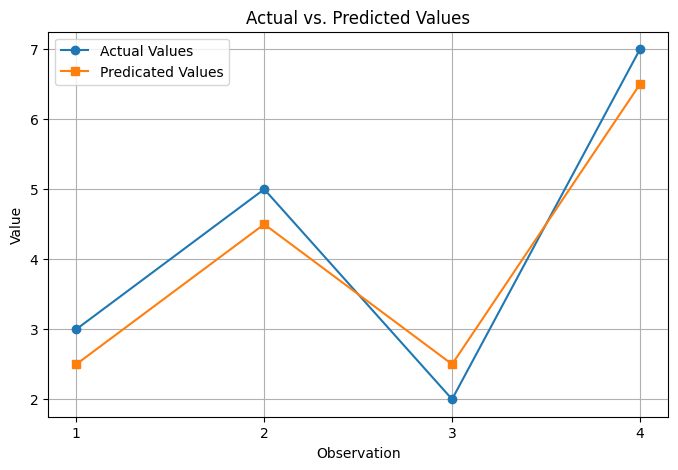

In [19]:
observations = np.arange(1, len(actual) + 1)
plt.figure(figsize=(8, 5))
plt.plot(
    observations,
    actual,
    marker="o",
    label="Actual Values"
)
plt.plot(
    observations,
    predicted,
    marker="s",
    label="Predicated Values"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.title("Actual vs. Predicted Values")
plt.xticks(observations)
plt.legend()
plt.grid(True)
plt.show()

- I will calculate binary cross-entropy using a small classification dataset.

In [21]:
actual_binary = np.array([1, 0, 1, 0])
predicted_probabilities = np.array([0.9, 0.2, 0.8, 0.1])
epsilon = 1e-15
p = np.clip(
    predicted_probabilities,
    epsilon,
    1 - epsilon
)
cross_entropy = -np.mean(
    actual_binary * np.log(1 - p)
)
print("Actual labels:", actual_binary)
print("Predicted probabilities:", predicted_probabilities)
print("Binary Cross-Entropy:", round(cross_entropy, 4))

Actual labels: [1 0 1 0]
Predicted probabilities: [0.9 0.2 0.8 0.1]
Binary Cross-Entropy: 0.978


- I will compare the binary cross-entropy of accurate probability predictions with inaccurate probability predictions.

In [22]:
good_predictions = np.array([0.9, 0.1, 0.8, 0.2])
bad_predictions = np.array([0.2, 0.8, 0.3, 0.7])
def binary_cross_entropy(y, p):
  p = np.clip(p, 1e-15, 1 - 1e-15)
  return -np.mean(
      y * np.log(p)
      + (1 - y) * np.log(1 - p)
  )
good_loss = binary_cross_entropy(
    actual_binary, good_predictions
)
bad_loss = binary_cross_entropy(
    actual_binary, bad_predictions
)
print("Good predictions loss:", round(good_loss, 4))
print("Bad predictions loss:", round(bad_loss, 4))

Good predictions loss: 0.1643
Bad predictions loss: 1.4067


- I will graph both cases to visualize how the cost function behaves

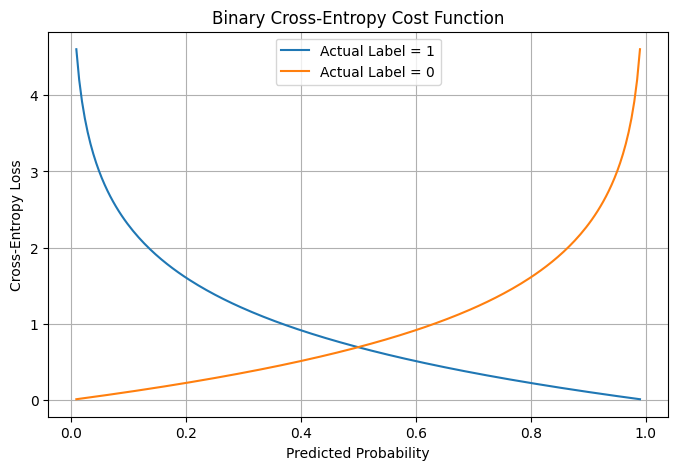

In [24]:
probabilities = np.linspace(0.01, 0.99, 200)
loss_y1 = -np.log(probabilities)
loss_y0 = -np.log(1 - probabilities)
plt.figure(figsize=(8, 5))
plt.plot(
    probabilities,
    loss_y1,
    label="Actual Label = 1"
)
plt.plot(
    probabilities,
    loss_y0,
    label="Actual Label = 0"
)
plt.xlabel("Predicted Probability")
plt.ylabel("Cross-Entropy Loss")
plt.title("Binary Cross-Entropy Cost Function")
plt.legend()
plt.grid(True)
plt.show()

- I wil create a simple example to demonstrate how gradient descent reduces the cost.

In [25]:
x = np.array([1, 2, 3, 4], dtype=float)
y = np.array([2, 4, 6, 8], dtype=float)
w = 0.0
learning_rate = 0.01
loss_history = []
for i in range(100):
  predictions = w * x
  loss = np.mean((predictions - y)**2)
  loss_history.append(loss)
  gradient = 2 * np.mean(
      (predictions - y) * x
  )
  w = w - learning_rate * gradient
  print("Final weight:", round(w, 4))
  print("Initial loss:", round(loss_history[0], 4))
  print("Final recorded loss:", round(loss_history[-1], 4))

Final weight: 0.3
Initial loss: 30.0
Final recorded loss: 30.0
Final weight: 0.555
Initial loss: 30.0
Final recorded loss: 21.675
Final weight: 0.7717
Initial loss: 30.0
Final recorded loss: 15.6602
Final weight: 0.956
Initial loss: 30.0
Final recorded loss: 11.3145
Final weight: 1.1126
Initial loss: 30.0
Final recorded loss: 8.1747
Final weight: 1.2457
Initial loss: 30.0
Final recorded loss: 5.9062
Final weight: 1.3588
Initial loss: 30.0
Final recorded loss: 4.2673
Final weight: 1.455
Initial loss: 30.0
Final recorded loss: 3.0831
Final weight: 1.5368
Initial loss: 30.0
Final recorded loss: 2.2275
Final weight: 1.6063
Initial loss: 30.0
Final recorded loss: 1.6094
Final weight: 1.6653
Initial loss: 30.0
Final recorded loss: 1.1628
Final weight: 1.7155
Initial loss: 30.0
Final recorded loss: 0.8401
Final weight: 1.7582
Initial loss: 30.0
Final recorded loss: 0.607
Final weight: 1.7945
Initial loss: 30.0
Final recorded loss: 0.4385
Final weight: 1.8253
Initial loss: 30.0
Final recorded 

- I will graph the cost function values recorded during gradient descent.

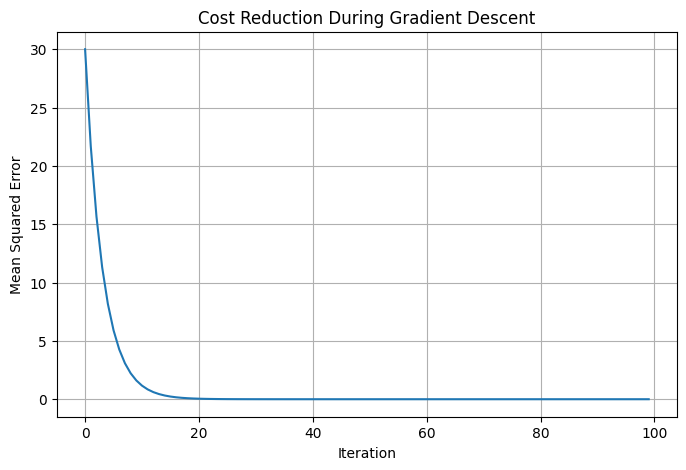

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Cost Reduction During Gradient Descent")
plt.grid(True)
plt.show()

Conclusion:
- In this section, I explored cost functions used in machine learning and neural networks.
- This example shows why cost functions are important for evaluating and improving machine learning models.

3.7.4. Backpropagation
- In this example, I will train a small neural network using backpropagation and visualize its learning progress.

In [27]:
print("Libraries imported successfully.")

Libraries imported successfully.


- I will create a small binary classification dataset containing two input features.

In [39]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y= np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

print("Input data:")
print(X)
print("Actual outputs:")
print(y)

Input data:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Actual outputs:
[[0.]
 [1.]
 [1.]
 [0.]]


- I will initialize the weights randomly and set the biases to zero.

In [40]:
np.random.seed(42)
W1 = np.random.randn(2, 4) * 0.5
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * 0.5
b2 = np.zeros((1, 1))
def sigmoid(z):
  return 1 / (1 + np.exp(-z))
print("Hidden layer weights shape:", W1.shape)
print("Output layer weights shape:", W2.shape)

Hidden layer weights shape: (2, 4)
Output layer weights shape: (4, 1)


- I will use forward prpopgation to calculate the network's initial predictions.

In [41]:
Z1 = X @ W1 + b1
A1 = np.tanh(Z1)
Z2 = A1 @ W2 + b2
A2 = sigmoid(Z2)
print("Initial predictions:")
print(np.round(A2, 4))

Initial predictions:
[[0.5   ]
 [0.4398]
 [0.4261]
 [0.3876]]


In [42]:
def binary_cross_entropy(y_true, y_pred):
  eps = 1e-12
  y_pred = np.clip(y_pred, eps, 1 - eps)
  return -np.mean(
      y_true * np.log(y_pred)
      + (1 - y_true) * np.log(1 - y_pred)
  )
initial_loss = binary_cross_entropy(y, A2)
print("Initial loss:", round(initial_loss, 4))

Initial loss: 0.7145


In [44]:
learning_rate = 0.5
epochs = 10000

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Calculate loss
    loss = binary_cross_entropy(y, A2)
    loss_history.append(loss)

    # Backpropagation
    dZ2 = A2 - y
    dW2 = A1.T @ dZ2 / len(X)
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dZ1 = (dZ2 @ W2.T) * (1 - A1**2)
    dW1 = X.T @ dZ1 / len(X)
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # Gradient descent updates
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

print("Training completed.")
print("Initial loss:", round(loss_history[0], 4))
print("Final loss:", round(loss_history[-1], 4))

Training completed.
Initial loss: 0.7145
Final loss: 0.0005


- I will compare the predictions with the actual outputs to evaluate the model.

In [45]:
Z1 = X @ W1 + b1
A1 = np.tanh(Z1)

Z2 = A1 @ W2 + b2
final_predictions = sigmoid(Z2)

predicted_classes = (final_predictions >= 0.5).astype(int)

print("Predicted probabilities:")
print(np.round(final_predictions, 4))

print("\nPredicted classes:")
print(predicted_classes)

print("\nActual classes:")
print(y.astype(int))

accuracy = np.mean(predicted_classes == y)

print("\nTraining accuracy:", round(accuracy, 4))

Predicted probabilities:
[[0.000e+00]
 [9.995e-01]
 [9.995e-01]
 [8.000e-04]]

Predicted classes:
[[0]
 [1]
 [1]
 [0]]

Actual classes:
[[0]
 [1]
 [1]
 [0]]

Training accuracy: 1.0


- I will graph the cost function values recorded during training.

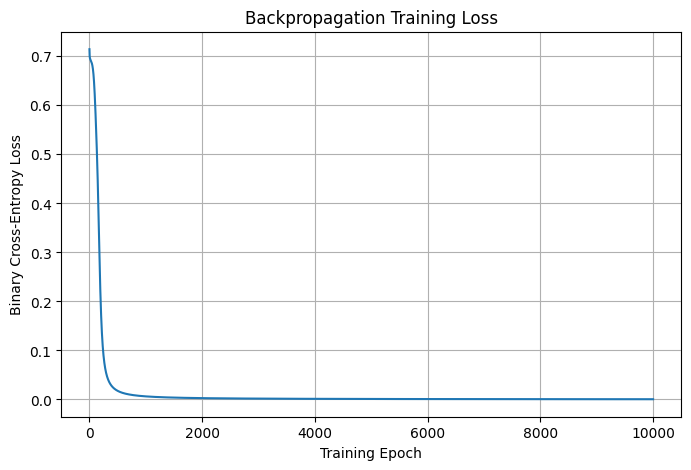

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Training Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Backpropagation Training Loss")
plt.grid(True)

plt.show()

- I will now compare the actual XOR outputs with the predications made by the trained network.

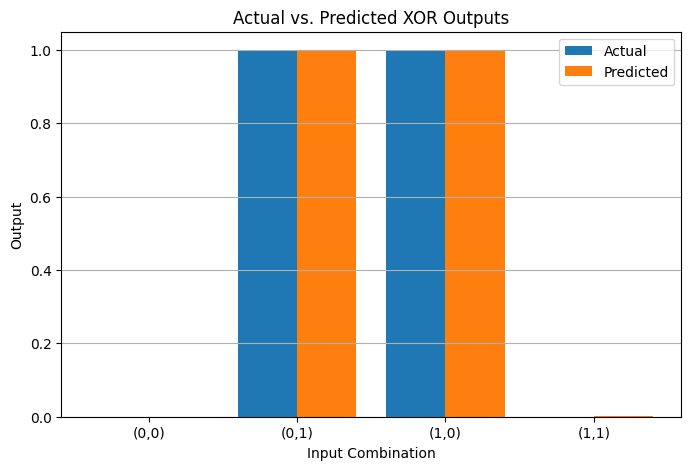

In [47]:
labels = ["(0,0)", "(0,1)", "(1,0)", "(1,1)"]

positions = np.arange(len(labels))

plt.figure(figsize=(8, 5))

plt.bar(
    positions - 0.2,
    y.flatten(),
    width=0.4,
    label="Actual"
)

plt.bar(
    positions + 0.2,
    final_predictions.flatten(),
    width=0.4,
    label="Predicted"
)

plt.xticks(positions, labels)

plt.xlabel("Input Combination")
plt.ylabel("Output")
plt.title("Actual vs. Predicted XOR Outputs")
plt.legend()
plt.grid(True, axis="y")

plt.show()

Conclusion:
- In this section, I explored backpropagation as a method for training neural networks.
- This example demonstrates how backpropagtion allows neural networks to learn nonlinear patterns by minimizing prediction errors.

3.7.5. Backpropagation algorithm
- In this example, I will use Python to demonstrate how backpropagation improves predictions.

In [48]:
x = 2.0
y = 1.0
w = 0.0
b = 0.0
learning_rate = 0.5
loss_history = []

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for i in range(100):
    prediction = sigmoid(w*x + b)
    loss = 0.5 * (prediction - y)**2
    loss_history.append(loss)

    # Backpropagation using the chain rule
    delta = (prediction - y) * prediction * (1 - prediction)

    # Update weight and bias
    w -= learning_rate * delta * x
    b -= learning_rate * delta

print("Initial loss:", round(loss_history[0], 4))
print("Final loss:", round(loss_history[-1], 4))
print("Final prediction:", round(sigmoid(w*x + b), 4))

Initial loss: 0.125
Final loss: 0.0012
Final prediction: 0.9512


- I will graph the loss during training to show how backpropagation reduces prediction errors.

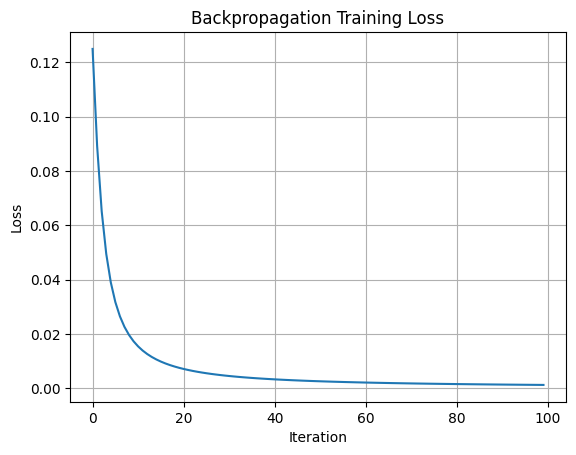

In [49]:
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Backpropagation Training Loss")
plt.grid(True)
plt.show()

Conclusion:
- In this section, I used backpropagation to update a neuron's weight and bias.
- All these examples showcase what each section in the book discusses.